In [1]:
import pandas as pd
import polars as pl
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
outputs_dir = "../3_outputs/sqY2H"

df = pl.read_csv(f'edges_df_luke.csv', null_values=".", infer_schema_length=10000)

# dedup
df = df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
)
df = df.with_columns(
    (pl.col("symbol") + "_" + 
     pl.col("ad_symbol") + "_" + 
     pl.col("aa_change")).alias("ppi_group_clean")
)

df = df.sort("db_mut_id", descending=True).unique(subset=["ppi_group_clean"], keep="first")

df
# drop WT

df = df.filter(pl.col("db_mut_id") != 0)

df = df.to_pandas()

df

,db_mut_id,symbol,ad_symbol,aa_change,log2fc,clinvar_clnsig_clean_pp_strict,ppi_group_clean
0,201376,GRN,LCE4A,Thr182Met,0.400748,Likely benign,GRN_LCE4A_Thr182Met
1,200837,MLH1,MAGEA8,Val185Gly,-4.717674,Pathogenic,MLH1_MAGEA8_Val185Gly
2,1835,STXBP1,TRIM38,Val451Ile,-0.315776,Likely benign,STXBP1_TRIM38_Val451Ile
3,2682,LITAF,EPN1,Val81Met,-1.641146,Likely benign,LITAF_EPN1_Val81Met
4,205673,UBQLN2,RBFOX2,Pro497His,-0.334945,Pathogenic,UBQLN2_RBFOX2_Pro497His
...,...,...,...,...,...,...,...
1858,213584,EZH2,EED,Arg684Cys,-0.790082,Pathogenic,EZH2_EED_Arg684Cys
1859,205675,UBQLN2,JPH4,Pro506Thr,0.043410,Pathogenic,UBQLN2_JPH4_Pro506Thr
1860,1808,STXBP1,CENPP,Thr248Ile,-5.143584,Conflicting,STXBP1_CENPP_Thr248Ile
1861,200934,HMBS,PICK1,Leu177Arg,-1.149963,Pathogenic,HMBS_PICK1_Leu177Arg


# Manual optimizer and classifier

Optimizing parameters...

=== OPTIMIZED PARAMETERS ===
WT Intrinsic Sigma:   0.0100
Mutant Mean:          -3.6715
Mutant Intrinsic Sig: 2.4111
Measurement Error:    0.5622
Bound (Fixed):        -1.5000


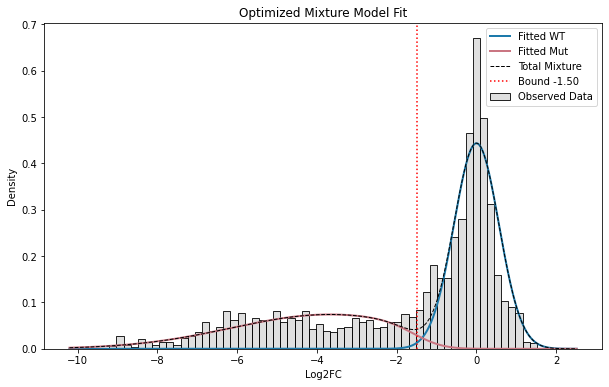


=== CUTOFFS ===
Log2FC at LLR > 3 (WT):      -0.7633
Log2FC at LLR < -3 (Mutant): -1.7563


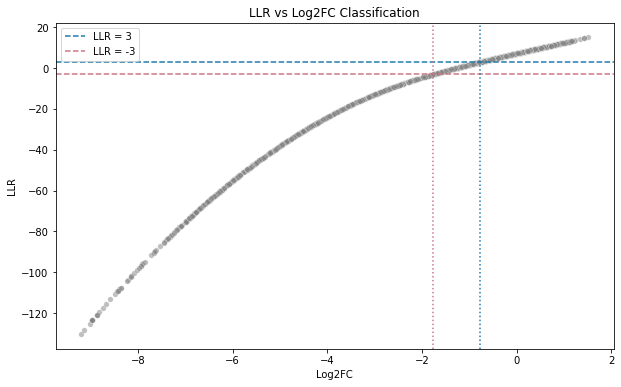

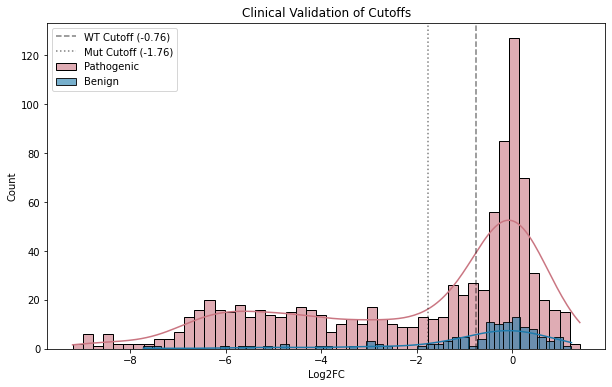

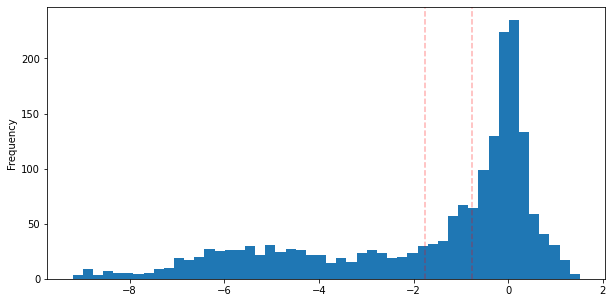

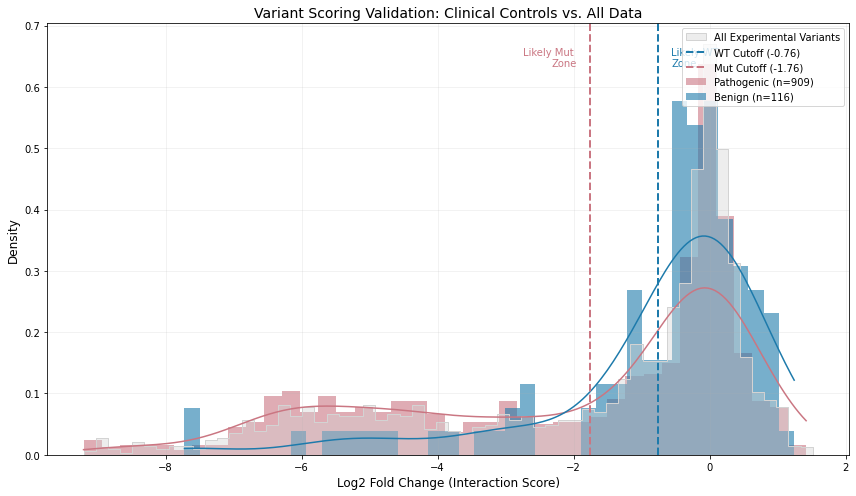

In [274]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
log2fc_values = df['log2fc'].dropna().to_numpy()
FIXED_BOUND = -1.5 # Hard biological limit

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def get_convolved_pdf(x_data, mu, sigma_bio, bound, sigma_error):
    """
    Computes the PDF of a Truncated Normal (intrinsic) convolved with Normal (noise).
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    # A. Un-truncated distribution (Prior + Noise)
    log_py = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)
    
    # B. Posterior Parameters for the Truncation Term
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)
    
    # C. Truncation Adjustment Terms
    t = (bound - mu_post) / sigma_post
    log_post_cdf = stats.norm.logcdf(t)
    
    alpha = (bound - mu) / sigma_bio
    log_Z = stats.norm.logcdf(alpha)
    
    # Final Log PDF
    log_result = log_py + log_post_cdf - log_Z
    return np.exp(log_result)

def negative_log_likelihood(params):
    """
    Objective function for optimization.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error = params
    
    # Constraints
    if sigma_wt < 0.01 or sigma_mut < 0.01 or w_mut < 0.01 or w_mut > 0.99 or sigma_error < 0.01:
        return np.inf
    
    # --- WT COMPONENT (Standard Normal Convolution) ---
    sigma_total_wt = np.sqrt(sigma_wt**2 + sigma_error**2)
    pdf_wt = stats.norm.pdf(log2fc_values, loc=0, scale=sigma_total_wt)
    
    # --- MUTANT COMPONENT (Truncated Convolution) ---
    pdf_mut = get_convolved_pdf(log2fc_values, mu_mut, sigma_mut, FIXED_BOUND, sigma_error)
    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    
    return -np.sum(np.log(pdf_mix))

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error
initial_guess = [0.3, -6.0, 2.0, 0.2, 0.5]

bounds = [
    (0.01, 1.0),    # sigma_wt
    (-12.0, -2.0),  # mu_mut
    # (-5, -5),  # mu_mut
    (0.5, 10.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.01, 0.99)    # sigma_error
]

print("Optimizing parameters...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

# Unpack optimized parameters
opt_sigma_wt, opt_mu_mut, opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"WT Intrinsic Sigma:   {opt_sigma_wt:.4f}")
print(f"Mutant Mean:          {opt_mu_mut:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bound (Fixed):        {FIXED_BOUND:.4f}")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(log2fc_values, stat='density', bins=60, color='silver', alpha=0.5, label='Observed Data')

x_plot = np.linspace(min(log2fc_values)-1, max(log2fc_values)+1, 1000)

# WT Curve
sigma_total_wt = np.sqrt(opt_sigma_wt**2 + opt_sigma_error**2)
y_wt = (1 - opt_w_mut) * stats.norm.pdf(x_plot, loc=0, scale=sigma_total_wt)

# Mut Curve
y_mut_raw = get_convolved_pdf(x_plot, opt_mu_mut, opt_sigma_mut, FIXED_BOUND, opt_sigma_error)
y_mut = opt_w_mut * y_mut_raw

# Total
y_total = y_wt + y_mut

plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_total, color='black', linestyle='--', lw=1, label='Total Mixture')
plt.axvline(FIXED_BOUND, color='red', linestyle=':', label=f'Bound {FIXED_BOUND:.2f}')

plt.title("Optimized Mixture Model Fit")
plt.xlabel("Log2FC")
plt.ylabel("Density")
plt.legend()
plt.show()

# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr(df_in, mu_mut, sigma_mut, sigma_wt, bound, sigma_error):
    """
    Calculates LLR using the consistent optimized parameters.
    """
    # Work on a copy (Pandas)
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()
        
    log2fc = df_out["log2fc"].to_numpy()
    
    # Handle row-specific error if available, otherwise use optimized global error
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)
        
    row_error = np.maximum(row_error, 1e-3) # Safety floor

    # --- Null Hypothesis (WT) ---
    # Model: Normal(0, scale = sqrt(Error^2 + Intrinsic_WT^2))
    scale_wt = np.sqrt(row_error**2 + sigma_wt**2)
    loglik_wt = stats.norm.logpdf(log2fc, loc=0, scale=scale_wt)
    
    # --- Alt Hypothesis (Mutant) ---
    # Model: Convolved Truncated Normal
    pdt_mut = get_convolved_pdf(log2fc, mu_mut, sigma_mut, bound, row_error)
    loglik_mut = np.log(np.maximum(pdt_mut, 1e-100))  # Safety floor
    
    # --- Final Score ---
    # LLR = Log(P(WT)) - Log(P(Mut))
    # Positive = WT, Negative = Mutant
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut
    
    return pl.from_pandas(df_out)

# Run Calculation
df_result_pl = compute_perturbation_llr(
    df, 
    mu_mut=opt_mu_mut, 
    sigma_mut=opt_sigma_mut, 
    sigma_wt=opt_sigma_wt, 
    bound=FIXED_BOUND, 
    sigma_error=opt_sigma_error
)
df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & VALIDATION PLOTS
# ==========================================
df_sorted = df_result.sort_values('perturbation_LLR')
x_vals = df_sorted['log2fc'].values
y_vals = df_sorted['perturbation_LLR'].values

# Interpolate Cutoffs
cutoff_wt = np.interp(3, y_vals, x_vals)
cutoff_mut = np.interp(-3, y_vals, x_vals)

print(f"\n=== CUTOFFS ===")
print(f"Log2FC at LLR > 3 (WT):      {cutoff_wt:.4f}")
print(f"Log2FC at LLR < -3 (Mutant): {cutoff_mut:.4f}")

# Plot 1: LLR Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=30)
plt.axhline(3, color='#1D7AAB', ls='--', label='LLR = 3')
plt.axhline(-3, color='#CA7682', ls='--', label='LLR = -3')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("LLR vs Log2FC Classification")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.legend()
plt.show()

# Plot 2: Pathogenic vs Benign Validation
pathogenic_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
).to_pandas()

benign_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
).to_pandas()

plt.figure(figsize=(10, 6))
sns.histplot(pathogenic_df["log2fc"], bins=50, kde=True, color="#CA7682", label="Pathogenic", alpha=0.6)
sns.histplot(benign_df["log2fc"], bins=50, kde=True, color="#1D7AAB", label="Benign", alpha=0.6)

plt.axvline(x=cutoff_wt, color='black', linestyle='--', alpha=0.5, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='black', linestyle=':', alpha=0.5, label=f'Mut Cutoff ({cutoff_mut:.2f})')

plt.title("Clinical Validation of Cutoffs")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# Plot combined histogram
df.log2fc.plot.hist(bins=50, figsize=(10,5))
plt.axvline(x=cutoff_wt, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_mut, color='red', linestyle='--', alpha=0.3)
plt.show()


plt.figure(figsize=(12, 7))



# 2. Foreground: Pathogenic Variants
sns.histplot(
    pathogenic_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#CA7682", 
    label=f"Pathogenic (n={len(pathogenic_df)})", 
    alpha=0.6,
    edgecolor=None # Removes bar edges for cleaner look on top of grey
)

# 3. Foreground: Benign Variants
sns.histplot(
    benign_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#1D7AAB", 
    label=f"Benign (n={len(benign_df)})", 
    alpha=0.6,
    edgecolor=None
)

# 1. Background: Full Dataset (Context)
# We use 'density' so it can be compared with the smaller clinical subsets
sns.histplot(
    log2fc_values, 
    stat='density', 
    bins=60, 
    color='lightgrey', 
    alpha=0.4, 
    label='All Experimental Variants',
    element="step",  # 'step' makes the outline cleaner for the background
    fill=True
)

# 4. Cutoff Lines
plt.axvline(x=cutoff_wt, color='#1D7AAB', linestyle='--', linewidth=2, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='#CA7682', linestyle='--', linewidth=2, label=f'Mut Cutoff ({cutoff_mut:.2f})')

# Annotations (Optional but helpful)
plt.text(cutoff_wt + 0.2, plt.ylim()[1]*0.9, "Likely WT \nZone", color='#1D7AAB', ha='left')
plt.text(cutoff_mut - 0.2, plt.ylim()[1]*0.9, "Likely Mut \nZone", color='#CA7682', ha='right')

plt.title("Variant Scoring Validation: Clinical Controls vs. All Data", fontsize=14)
plt.xlabel("Log2 Fold Change (Interaction Score)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Chatgpt implementation of two trunc

Optimizing parameters...

=== OPTIMIZED PARAMETERS ===
WT Intrinsic Sigma:   0.0100
Mutant Mean:          -3.4410
Mutant Intrinsic Sig: 2.6591
Measurement Error:    0.5575
Bound (Fixed):        -1.5000


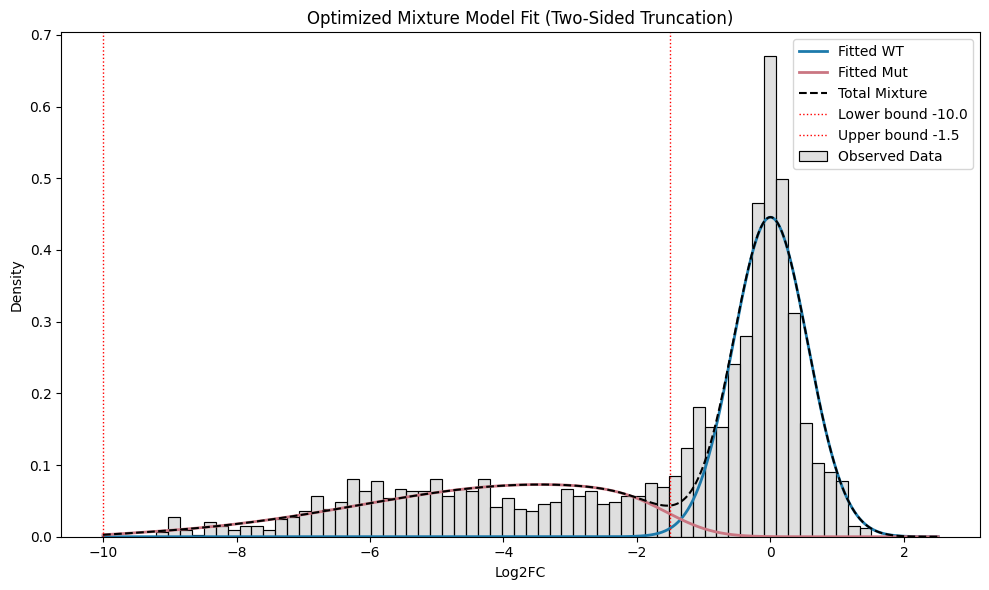


=== CUTOFFS ===
Log2FC at LLR > 3 (WT):      -0.7504
Log2FC at LLR < -3 (Mutant): -1.7356


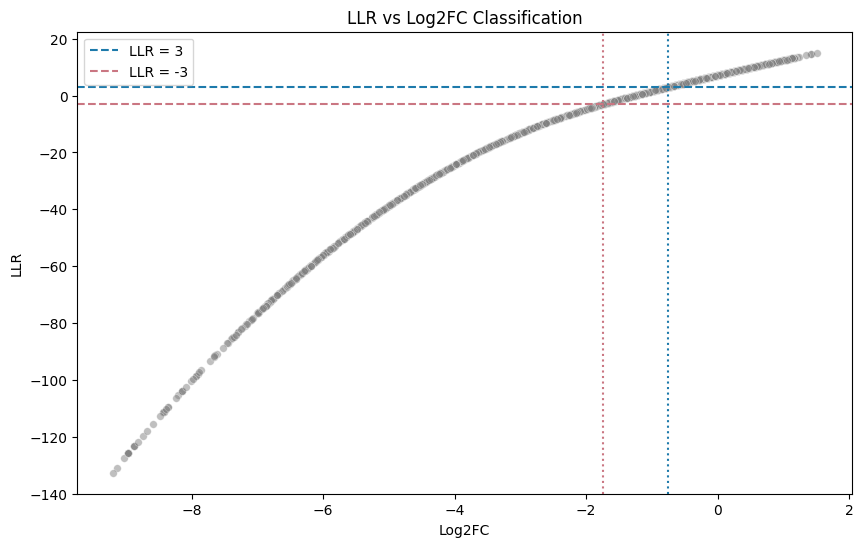

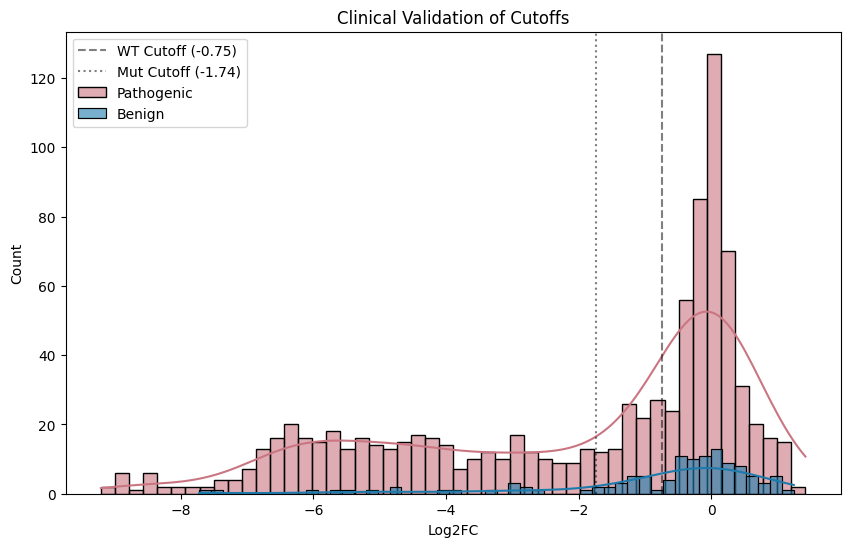

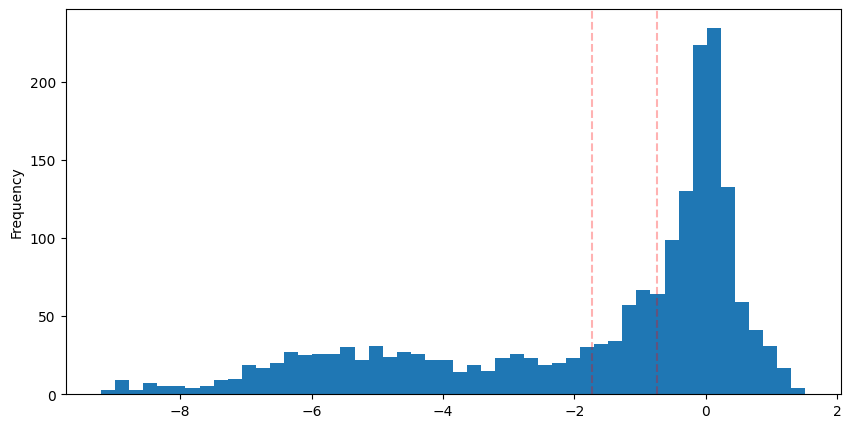

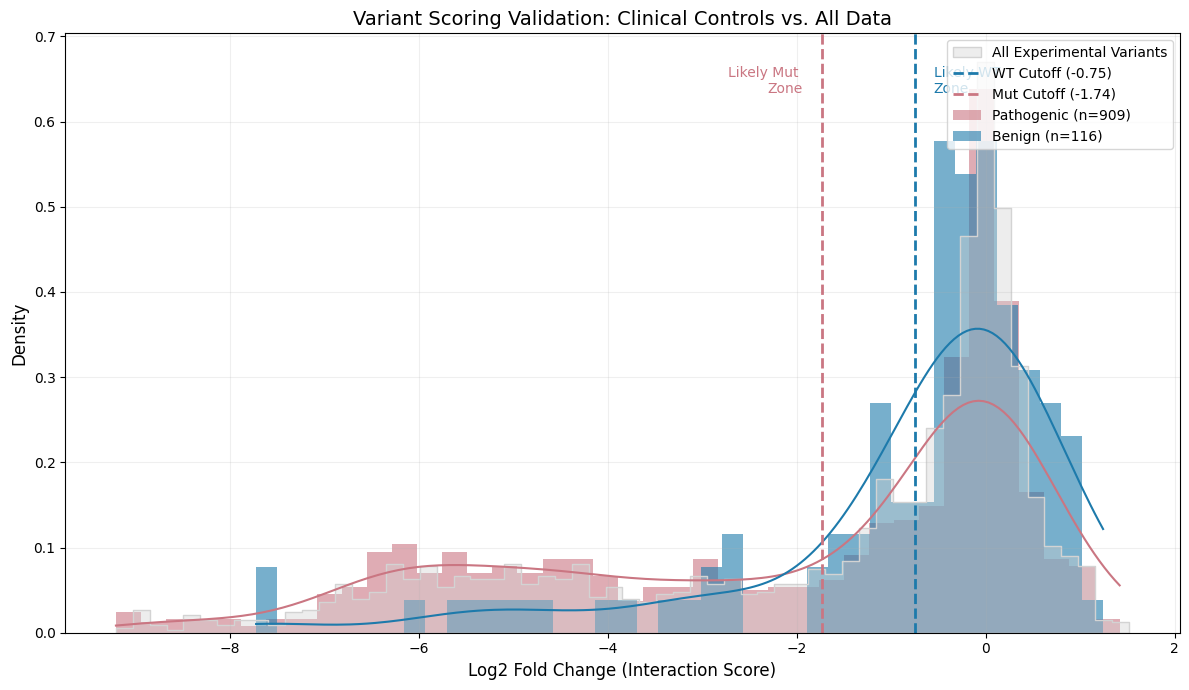

In [3]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
log2fc_values = df['log2fc'].dropna().to_numpy()
RIGHT_BOUND = -1.5 # Hard biological limit
LEFT_BOUND = -10.0 # For numerical stability in truncation

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================

def _logdiffexp(a, b):
    """log(exp(a) - exp(b)) stable, assumes a > b."""
    return a + np.log1p(-np.exp(b - a))

def get_convolved_pdf_two_sided(x_data, mu, sigma_bio, lower, upper, sigma_error):
    """
    PDF of (Truncated Normal intrinsic on [lower, upper]) convolved with Normal noise.
    This generalizes your one-sided formula to two-sided truncation.
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)

    # A) Untruncated (prior + noise)
    log_py = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)

    # B) Posterior params used in truncation factor
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)

    # C) Two-sided truncation adjustment using posterior CDF window
    t_hi = (upper - mu_post) / sigma_post
    t_lo = (lower - mu_post) / sigma_post

    # log(Φ(t_hi) - Φ(t_lo)) stably
    logPhi_hi = stats.norm.logcdf(t_hi)
    logPhi_lo = stats.norm.logcdf(t_lo)

    # ensure hi >= lo numerically
    log_post_window = np.where(
        t_hi > t_lo,
        _logdiffexp(logPhi_hi, logPhi_lo),
        -np.inf
    )

    # D) Prior normalization over [lower, upper]
    a_hi = (upper - mu) / sigma_bio
    a_lo = (lower - mu) / sigma_bio
    logZ_hi = stats.norm.logcdf(a_hi)
    logZ_lo = stats.norm.logcdf(a_lo)

    log_Z = _logdiffexp(logZ_hi, logZ_lo)

    # Final log pdf
    log_result = log_py + log_post_window - log_Z
    return np.exp(log_result)

def negative_log_likelihood(params):
    """
    Objective function for optimization.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error = params
    
    # Constraints
    if sigma_wt < 0.01 or sigma_mut < 0.01 or w_mut < 0.01 or w_mut > 0.99 or sigma_error < 0.01:
        return np.inf
    
    # --- WT COMPONENT (Standard Normal Convolution) ---
    sigma_total_wt = np.sqrt(sigma_wt**2 + sigma_error**2)
    pdf_wt = stats.norm.pdf(log2fc_values, loc=0, scale=sigma_total_wt)
    
    # --- MUTANT COMPONENT (Truncated Convolution) ---
    pdf_mut = get_convolved_pdf_two_sided(
    log2fc_values, mu_mut, sigma_mut,
    LEFT_BOUND, RIGHT_BOUND,
    sigma_error
)

    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    
    return -np.sum(np.log(pdf_mix))

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error
initial_guess = [0.3, -6.0, 2.0, 0.2, 0.5]

bounds = [
    (0.01, 1.0),    # sigma_wt
    (-10.0, -2.0),  # mu_mut
    # (-5, -5),  # mu_mut
    (0.5, 10.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.01, 0.99)    # sigma_error
]

print("Optimizing parameters...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

# Unpack optimized parameters
opt_sigma_wt, opt_mu_mut, opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"WT Intrinsic Sigma:   {opt_sigma_wt:.4f}")
print(f"Mutant Mean:          {opt_mu_mut:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bound (Fixed):        {RIGHT_BOUND:.4f}")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================

plt.figure(figsize=(10, 6))
sns.histplot(
    log2fc_values,
    stat='density',
    bins=60,
    color='silver',
    alpha=0.5,
    label='Observed Data'
)

# Plot range must include full truncation support
x_plot = np.linspace(LEFT_BOUND, max(log2fc_values) + 1, 2000)

# --- WT Curve (unchanged) ---
sigma_total_wt = np.sqrt(opt_sigma_wt**2 + opt_sigma_error**2)
y_wt = (1 - opt_w_mut) * stats.norm.pdf(
    x_plot, loc=0, scale=sigma_total_wt
)

# --- Mutant Curve (two-sided truncated convolution) ---
y_mut_raw = get_convolved_pdf_two_sided(
    x_plot,
    opt_mu_mut,
    opt_sigma_mut,
    LEFT_BOUND,
    RIGHT_BOUND,
    opt_sigma_error
)
y_mut = opt_w_mut * y_mut_raw

# --- Total mixture ---
y_total = y_wt + y_mut

# --- Plot ---
plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_total, color='black', linestyle='--', lw=1.5, label='Total Mixture')

# Truncation bounds
plt.axvline(LEFT_BOUND, color='red', linestyle=':', lw=1, label=f'Lower bound {LEFT_BOUND}')
plt.axvline(RIGHT_BOUND, color='red', linestyle=':', lw=1, label=f'Upper bound {RIGHT_BOUND}')

plt.title("Optimized Mixture Model Fit (Two-Sided Truncation)")
plt.xlabel("Log2FC")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()


# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr(df_in, mu_mut, sigma_mut, sigma_wt, lower_bound, upper_bound, sigma_error):
    """
    Calculates LLR using consistent optimized parameters.
    LLR = log p(x | WT) - log p(x | Mut)
    Mutant model: truncated intrinsic Normal on [lower_bound, upper_bound] convolved with Normal error.
    """
    # Work on a copy (Pandas)
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()

    log2fc = df_out["log2fc"].to_numpy()

    # Handle row-specific error if available, otherwise use optimized global error
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)

    row_error = np.maximum(row_error, 1e-3)  # Safety floor

    # --- Null Hypothesis (WT) ---
    scale_wt = np.sqrt(row_error**2 + sigma_wt**2)
    loglik_wt = stats.norm.logpdf(log2fc, loc=0, scale=scale_wt)

    # --- Alt Hypothesis (Mutant) ---
    p_mut = get_convolved_pdf_two_sided(
        log2fc,
        mu_mut,
        sigma_mut,
        lower_bound,
        upper_bound,
        row_error
    )
    loglik_mut = np.log(np.maximum(p_mut, 1e-100))  # Safety floor

    # --- Final Score ---
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut

    return pl.from_pandas(df_out)

# Run Calculation
df_result_pl = compute_perturbation_llr(
    df,
    mu_mut=opt_mu_mut,
    sigma_mut=opt_sigma_mut,
    sigma_wt=opt_sigma_wt,
    lower_bound=LEFT_BOUND,
    upper_bound=RIGHT_BOUND,
    sigma_error=opt_sigma_error
)

df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & VALIDATION PLOTS
# ==========================================
df_sorted = df_result.sort_values('perturbation_LLR')
x_vals = df_sorted['log2fc'].values
y_vals = df_sorted['perturbation_LLR'].values

# Interpolate Cutoffs
cutoff_wt = np.interp(3, y_vals, x_vals)
cutoff_mut = np.interp(-3, y_vals, x_vals)

print(f"\n=== CUTOFFS ===")
print(f"Log2FC at LLR > 3 (WT):      {cutoff_wt:.4f}")
print(f"Log2FC at LLR < -3 (Mutant): {cutoff_mut:.4f}")

# Plot 1: LLR Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=30)
plt.axhline(3, color='#1D7AAB', ls='--', label='LLR = 3')
plt.axhline(-3, color='#CA7682', ls='--', label='LLR = -3')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("LLR vs Log2FC Classification")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.legend()
plt.show()

# Plot 2: Pathogenic vs Benign Validation
pathogenic_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
).to_pandas()

benign_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
).to_pandas()

plt.figure(figsize=(10, 6))
sns.histplot(pathogenic_df["log2fc"], bins=50, kde=True, color="#CA7682", label="Pathogenic", alpha=0.6)
sns.histplot(benign_df["log2fc"], bins=50, kde=True, color="#1D7AAB", label="Benign", alpha=0.6)

plt.axvline(x=cutoff_wt, color='black', linestyle='--', alpha=0.5, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='black', linestyle=':', alpha=0.5, label=f'Mut Cutoff ({cutoff_mut:.2f})')

plt.title("Clinical Validation of Cutoffs")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# Plot combined histogram
df.log2fc.plot.hist(bins=50, figsize=(10,5))
plt.axvline(x=cutoff_wt, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_mut, color='red', linestyle='--', alpha=0.3)
plt.show()


plt.figure(figsize=(12, 7))



# 2. Foreground: Pathogenic Variants
sns.histplot(
    pathogenic_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#CA7682", 
    label=f"Pathogenic (n={len(pathogenic_df)})", 
    alpha=0.6,
    edgecolor=None # Removes bar edges for cleaner look on top of grey
)

# 3. Foreground: Benign Variants
sns.histplot(
    benign_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#1D7AAB", 
    label=f"Benign (n={len(benign_df)})", 
    alpha=0.6,
    edgecolor=None
)

# 1. Background: Full Dataset (Context)
# We use 'density' so it can be compared with the smaller clinical subsets
sns.histplot(
    log2fc_values, 
    stat='density', 
    bins=60, 
    color='lightgrey', 
    alpha=0.4, 
    label='All Experimental Variants',
    element="step",  # 'step' makes the outline cleaner for the background
    fill=True
)

# 4. Cutoff Lines
plt.axvline(x=cutoff_wt, color='#1D7AAB', linestyle='--', linewidth=2, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='#CA7682', linestyle='--', linewidth=2, label=f'Mut Cutoff ({cutoff_mut:.2f})')

# Annotations (Optional but helpful)
plt.text(cutoff_wt + 0.2, plt.ylim()[1]*0.9, "Likely WT \nZone", color='#1D7AAB', ha='left')
plt.text(cutoff_mut - 0.2, plt.ylim()[1]*0.9, "Likely Mut \nZone", color='#CA7682', ha='right')

plt.title("Variant Scoring Validation: Clinical Controls vs. All Data", fontsize=14)
plt.xlabel("Log2 Fold Change (Interaction Score)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Luke having a go at editing the CHATGPT code

Optimizing parameters...

=== OPTIMIZED PARAMETERS ===
WT Intrinsic Sigma Left:   0.6245
WT Intrinsic Sigma Right:   0.4443
Mutant Mean:          -4.1447
Mutant Intrinsic Sig: 2.3419
Measurement Error:    0.2000
Bound (Fixed):        -1.0000


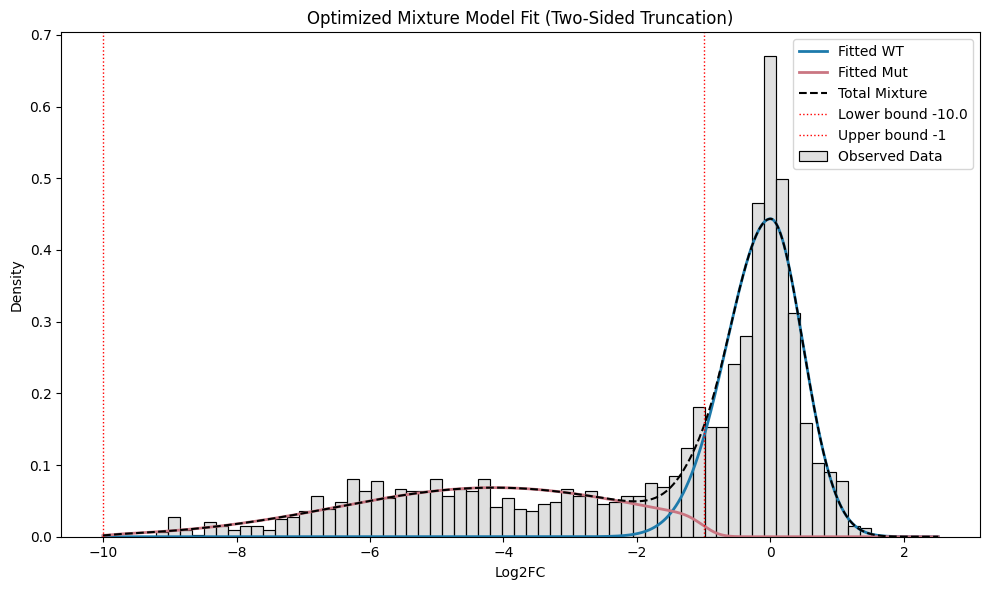


=== CUTOFFS ===
Log2FC at LLR > 3 (WT):      -1.0993
Log2FC at LLR < -3 (Mutant): -4.1438


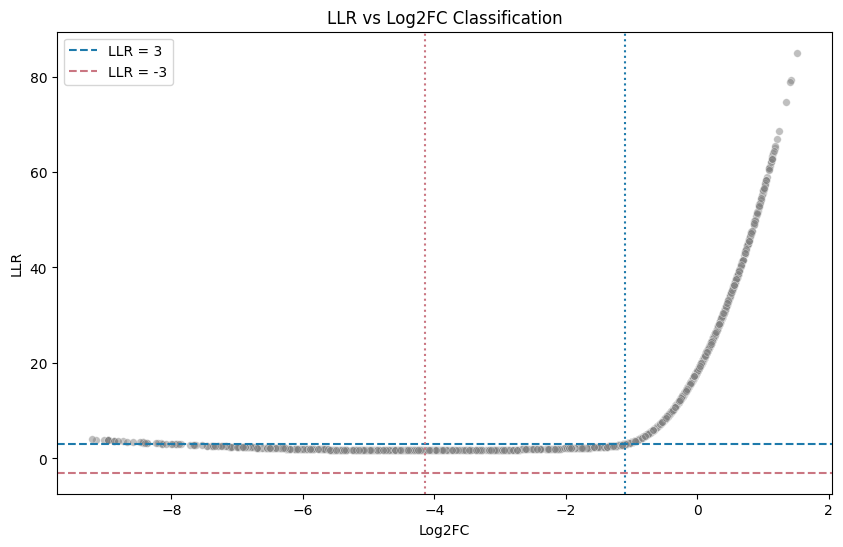

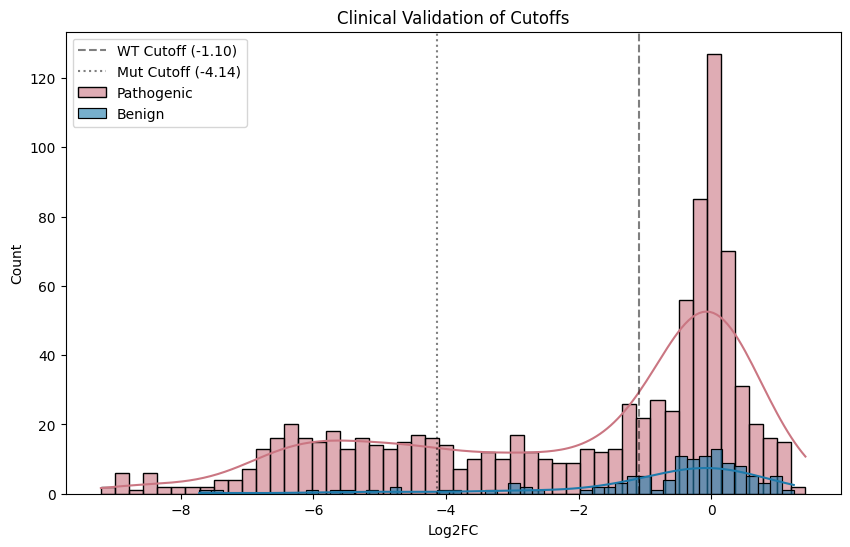

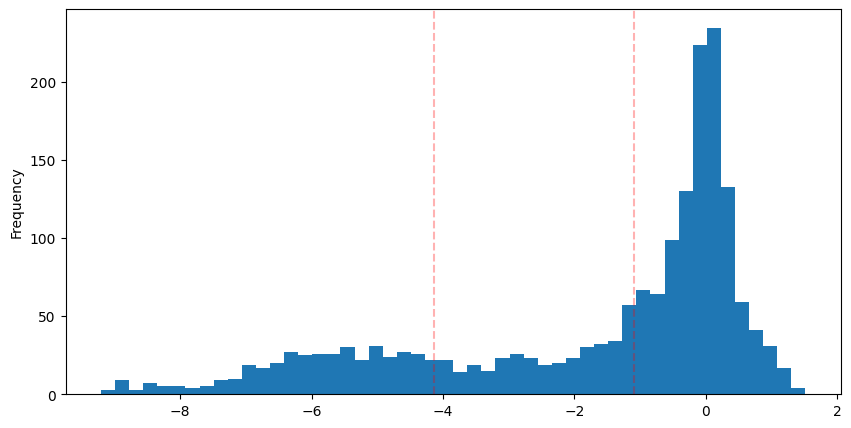

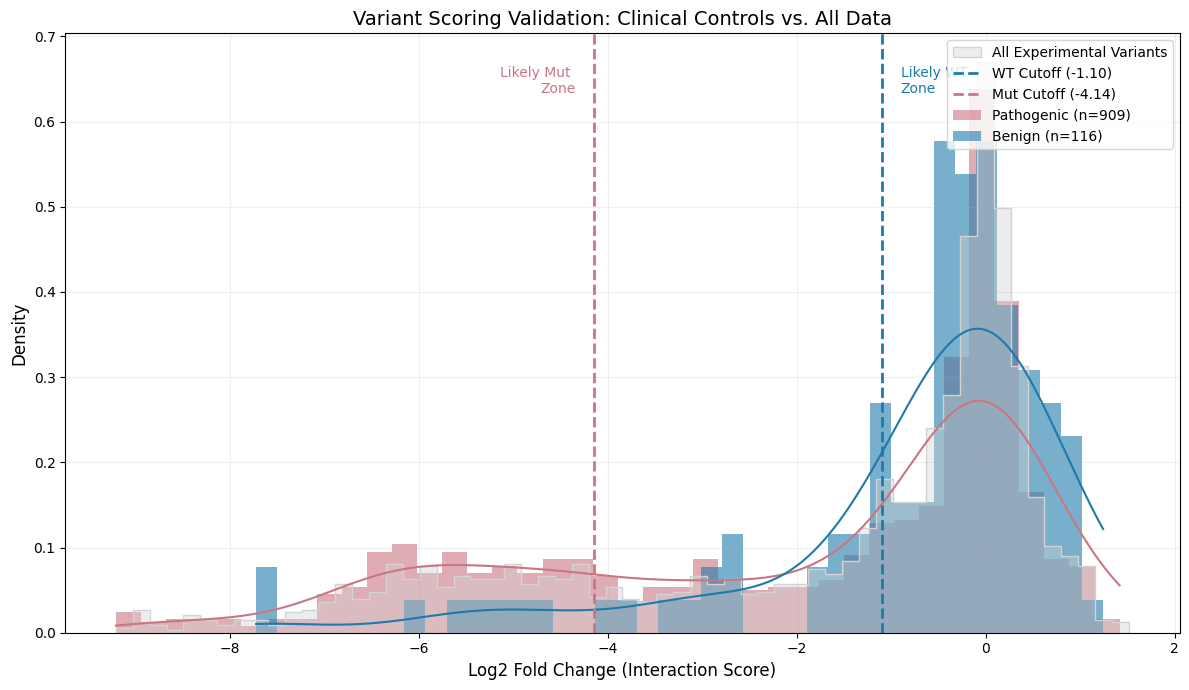

In [23]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import scipy.special as special
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
log2fc_values = df['log2fc'].dropna().to_numpy()
RIGHT_BOUND = -1 # Hard biological limit
LEFT_BOUND = -10.0 # For numerical stability in truncation

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================

def _logdiffexp(a, b):
    """log(exp(a) - exp(b)) stable, assumes a > b."""
    return a + np.log1p(-np.exp(b - a))

def get_convolved_pdf_two_sided(x_data, mu, sigma_bio, lower, upper, sigma_error):
    """
    PDF of (Truncated Normal intrinsic on [lower, upper]) convolved with Normal noise.
    This generalizes your one-sided formula to two-sided truncation.
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)

    # A) Untruncated (prior + noise)
    log_py = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)

    # B) Posterior params used in truncation factor
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)

    # C) Two-sided truncation adjustment using posterior CDF window
    t_hi = (upper - mu_post) / sigma_post
    t_lo = (lower - mu_post) / sigma_post

    # log(Φ(t_hi) - Φ(t_lo)) stably
    logPhi_hi = stats.norm.logcdf(t_hi)
    logPhi_lo = stats.norm.logcdf(t_lo)

    # ensure hi >= lo numerically
    log_post_window = np.where(
        t_hi > t_lo,
        _logdiffexp(logPhi_hi, logPhi_lo),
        -np.inf
    )

    # D) Prior normalization over [lower, upper]
    a_hi = (upper - mu) / sigma_bio
    a_lo = (lower - mu) / sigma_bio
    logZ_hi = stats.norm.logcdf(a_hi)
    logZ_lo = stats.norm.logcdf(a_lo)

    log_Z = _logdiffexp(logZ_hi, logZ_lo)

    # Final log pdf
    log_result = log_py + log_post_window - log_Z
    return np.exp(log_result)

##### LUKE: some chatgpt code for the tail probs

def trunc_y_interval_mass(L, U, mu0, sigma0, sigma_m, b):
    alpha = (b - mu0) / sigma0
    Z_theta = np.exp(special.log_ndtr(alpha))

    cov = np.array([[sigma0**2,            sigma0**2],
                    [sigma0**2, sigma0**2 + sigma_m**2]])
    mean = np.array([mu0, mu0])

    mvn = stats.multivariate_normal(mean=mean, cov=cov)

    p_joint_U = mvn.cdf([b, U])
    p_joint_L = mvn.cdf([b, L])

    num = p_joint_U - p_joint_L
    # clamp to [0, Z_theta] (since numerator is a subset of {theta<=b})
    num = min(max(num, 0.0), Z_theta)

    return num / max(Z_theta, 1e-300)


def splitnorm_logpdf(x, mu, sigma_left, sigma_right):
    """
    Two-piece (split) normal distribution.
    Continuous at x=mu, but with a kink (derivative changes) there.
    """
    x = np.asarray(x)
    sigma_left = np.maximum(sigma_left, 1e-12)
    sigma_right = np.maximum(sigma_right, 1e-12)

    # log(sqrt(2/pi)) - log(sigma_left + sigma_right)
    logC = 0.5*np.log(2/np.pi) - np.log(sigma_left + sigma_right)

    sig = np.where(x < mu, sigma_left, sigma_right)
    z = (x - mu) / sig

    return logC - 0.5 * z**2


def negative_log_likelihood(params):
    """
    Objective function for optimization.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_wt_left, sigma_wt_right, mu_mut, sigma_mut, w_mut, sigma_error = params
    
    # Constraints
    if sigma_wt_left < 0.01 or sigma_wt_right < 0.01 or sigma_mut < 0.01 or w_mut < 0.01 or w_mut > 0.99 or sigma_error < 0.01:
        return np.inf
    
    # --- WT COMPONENT (Split Normal Convoluted with Normal) ---
    sigma_total_wt_left = np.sqrt(sigma_wt_left**2 + sigma_error**2)
    sigma_total_wt_right = np.sqrt(sigma_wt_right**2 + sigma_error**2)
    
    pdf_wt = np.exp(splitnorm_logpdf(log2fc_values, mu=0,
                                 sigma_left=sigma_total_wt_left,
                                 sigma_right=sigma_total_wt_right))
    
    # --- MUTANT COMPONENT (Truncated Convolution) ---
    pdf_mut = get_convolved_pdf_two_sided(
    log2fc_values, mu_mut, sigma_mut,
    LEFT_BOUND, RIGHT_BOUND,
    sigma_error
)

    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    

    # --- LUKE: truncating the likeilihood since the data is truncated ---
    UPPER_BOUND_LIKELIHOOD = 2.
    LOWER_BOUND_LIKELIHOOD = -10
   
    # WT: Z_wt = P(L <= Y <= U)
    Z_wt = (
        (stats.norm.cdf(0, loc=0, scale=sigma_total_wt_left)
         - stats.norm.cdf(LOWER_BOUND_LIKELIHOOD, loc=0, scale=sigma_total_wt_left))
         +
        (stats.norm.cdf(UPPER_BOUND_LIKELIHOOD, loc=0, scale=sigma_total_wt_right)
        - stats.norm.cdf(0, loc=0, scale=sigma_total_wt_right))
    )

    # Mut: Z_mut = P(L <= Y <= U | theta <= RIGHT_BOUND)
    Z_mut = trunc_y_interval_mass(
        L=LOWER_BOUND_LIKELIHOOD,
        U=UPPER_BOUND_LIKELIHOOD,
        mu0=mu_mut,
        sigma0=sigma_mut,
        sigma_m=sigma_error,
        b=RIGHT_BOUND
    )

    # Mixture window mass
    Z_mix = (1 - w_mut) * Z_wt + w_mut * Z_mut

    # Safety (avoid log(0))
    Z_mix = max(Z_mix, 1e-300)

    return -np.sum(np.log(pdf_mix))
    #return -np.sum(np.log(pdf_mix)) + len(log2fc_values) * np.log(Z_mix)

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt_left, sigma_wt_right, mu_mut, sigma_mut, w_mut, sigma_error
initial_guess = [0.3, 0.3, -6.0, 2.0, 0.2, 0.5]

bounds = [
    (0.01, 1.0),    # sigma_wt_left
    (0.01, 1.0),    # sigma_wt_right
    (-6.0, -2.0),  # mu_mut
    # (-5, -5),  # mu_mut
    (0.5, 5.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.2, 0.99)    # sigma_error
]

print("Optimizing parameters...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

# Unpack optimized parameters
opt_sigma_wt_left, opt_sigma_wt_right, opt_mu_mut, opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"WT Intrinsic Sigma Left:   {opt_sigma_wt_left:.4f}")
print(f"WT Intrinsic Sigma Right:   {opt_sigma_wt_right:.4f}")
print(f"Mutant Mean:          {opt_mu_mut:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bound (Fixed):        {RIGHT_BOUND:.4f}")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================

plt.figure(figsize=(10, 6))
sns.histplot(
    log2fc_values,
    stat='density',
    bins=60,
    color='silver',
    alpha=0.5,
    label='Observed Data'
)

# Plot range must include full truncation support
x_plot = np.linspace(LEFT_BOUND, max(log2fc_values) + 1, 2000)

# --- WT Curve (unchanged) ---
sigma_total_wt_left = np.sqrt(opt_sigma_wt_left**2 + opt_sigma_error**2)
sigma_total_wt_right = np.sqrt(opt_sigma_wt_right**2 + opt_sigma_error**2)
y_wt = (1 - opt_w_mut) * np.exp(splitnorm_logpdf(x_plot, 0, sigma_total_wt_left, sigma_total_wt_right))

# --- Mutant Curve (two-sided truncated convolution) ---
y_mut_raw = get_convolved_pdf_two_sided(
    x_plot,
    opt_mu_mut,
    opt_sigma_mut,
    LEFT_BOUND,
    RIGHT_BOUND,
    opt_sigma_error
)
y_mut = opt_w_mut * y_mut_raw

# --- Total mixture ---
y_total = y_wt + y_mut

# --- Plot ---
plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_total, color='black', linestyle='--', lw=1.5, label='Total Mixture')

# Truncation bounds
plt.axvline(LEFT_BOUND, color='red', linestyle=':', lw=1, label=f'Lower bound {LEFT_BOUND}')
plt.axvline(RIGHT_BOUND, color='red', linestyle=':', lw=1, label=f'Upper bound {RIGHT_BOUND}')

plt.title("Optimized Mixture Model Fit (Two-Sided Truncation)")
plt.xlabel("Log2FC")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()


# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr(df_in, mu_mut, sigma_mut, sigma_wt_left, sigma_wt_right, lower_bound, upper_bound, sigma_error):
    """
    Calculates LLR using consistent optimized parameters.
    LLR = log p(x | WT) - log p(x | Mut)
    Mutant model: truncated intrinsic Normal on [lower_bound, upper_bound] convolved with Normal error.
    """
    # Work on a copy (Pandas)
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()

    log2fc = df_out["log2fc"].to_numpy()

    # Handle row-specific error if available, otherwise use optimized global error
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)

    row_error = np.maximum(row_error, 1e-3)  # Safety floor

    # --- Null Hypothesis (WT) ---
    scale_wt_left = np.sqrt(row_error**2 + sigma_wt_left**2)
    scale_wt_right = np.sqrt(row_error**2 + sigma_wt_right**2)
    loglik_wt = np.exp(splitnorm_logpdf(log2fc, 0, scale_wt_left, scale_wt_right))

    # --- Alt Hypothesis (Mutant) ---
    p_mut = get_convolved_pdf_two_sided(
        log2fc,
        mu_mut,
        sigma_mut,
        lower_bound,
        upper_bound,
        row_error
    )
    loglik_mut = np.log(np.maximum(p_mut, 1e-100))  # Safety floor

    # --- Final Score ---
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut

    return pl.from_pandas(df_out)

# Run Calculation
df_result_pl = compute_perturbation_llr(
    df,
    mu_mut=opt_mu_mut,
    sigma_mut=opt_sigma_mut,
    sigma_wt_left=opt_sigma_wt_left,
    sigma_wt_right=opt_sigma_wt_right,
    lower_bound=LEFT_BOUND,
    upper_bound=RIGHT_BOUND,
    sigma_error=opt_sigma_error
)

df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & VALIDATION PLOTS
# ==========================================
df_sorted = df_result.sort_values('perturbation_LLR')
x_vals = df_sorted['log2fc'].values
y_vals = df_sorted['perturbation_LLR'].values

# Interpolate Cutoffs
cutoff_wt = np.interp(3, y_vals, x_vals)
cutoff_mut = np.interp(-3, y_vals, x_vals)

print(f"\n=== CUTOFFS ===")
print(f"Log2FC at LLR > 3 (WT):      {cutoff_wt:.4f}")
print(f"Log2FC at LLR < -3 (Mutant): {cutoff_mut:.4f}")

# Plot 1: LLR Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=30)
plt.axhline(3, color='#1D7AAB', ls='--', label='LLR = 3')
plt.axhline(-3, color='#CA7682', ls='--', label='LLR = -3')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("LLR vs Log2FC Classification")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.legend()
plt.show()

# Plot 2: Pathogenic vs Benign Validation
pathogenic_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
).to_pandas()

benign_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
).to_pandas()

plt.figure(figsize=(10, 6))
sns.histplot(pathogenic_df["log2fc"], bins=50, kde=True, color="#CA7682", label="Pathogenic", alpha=0.6)
sns.histplot(benign_df["log2fc"], bins=50, kde=True, color="#1D7AAB", label="Benign", alpha=0.6)

plt.axvline(x=cutoff_wt, color='black', linestyle='--', alpha=0.5, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='black', linestyle=':', alpha=0.5, label=f'Mut Cutoff ({cutoff_mut:.2f})')

plt.title("Clinical Validation of Cutoffs")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# Plot combined histogram
df.log2fc.plot.hist(bins=50, figsize=(10,5))
plt.axvline(x=cutoff_wt, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_mut, color='red', linestyle='--', alpha=0.3)
plt.show()


plt.figure(figsize=(12, 7))



# 2. Foreground: Pathogenic Variants
sns.histplot(
    pathogenic_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#CA7682", 
    label=f"Pathogenic (n={len(pathogenic_df)})", 
    alpha=0.6,
    edgecolor=None # Removes bar edges for cleaner look on top of grey
)

# 3. Foreground: Benign Variants
sns.histplot(
    benign_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#1D7AAB", 
    label=f"Benign (n={len(benign_df)})", 
    alpha=0.6,
    edgecolor=None
)

# 1. Background: Full Dataset (Context)
# We use 'density' so it can be compared with the smaller clinical subsets
sns.histplot(
    log2fc_values, 
    stat='density', 
    bins=60, 
    color='lightgrey', 
    alpha=0.4, 
    label='All Experimental Variants',
    element="step",  # 'step' makes the outline cleaner for the background
    fill=True
)

# 4. Cutoff Lines
plt.axvline(x=cutoff_wt, color='#1D7AAB', linestyle='--', linewidth=2, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='#CA7682', linestyle='--', linewidth=2, label=f'Mut Cutoff ({cutoff_mut:.2f})')

# Annotations (Optional but helpful)
plt.text(cutoff_wt + 0.2, plt.ylim()[1]*0.9, "Likely WT \nZone", color='#1D7AAB', ha='left')
plt.text(cutoff_mut - 0.2, plt.ylim()[1]*0.9, "Likely Mut \nZone", color='#CA7682', ha='right')

plt.title("Variant Scoring Validation: Clinical Controls vs. All Data", fontsize=14)
plt.xlabel("Log2 Fold Change (Interaction Score)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
def my_likelihood(x, theta):
    ASSUMED_PERTURBATION_BOUND = -1.5
    log2fc = x
    error_log2fc, ASSUMED_PERTURBATION_DISTRIBUTION, ASSUMED_PERTURBATION_SIZE = theta

    var_prior = ASSUMED_PERTURBATION_DISTRIBUTION**2
    var_measurement = error_log2fc**2
    sigma_combined = np.sqrt(var_prior + var_measurement)

    # Marginal (untruncated) distribution of y
    log_py = stats.norm.logpdf(
        log2fc, loc=ASSUMED_PERTURBATION_SIZE, scale=sigma_combined
    )

    # Posterior of theta | y under untruncated normal prior
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (
        ASSUMED_PERTURBATION_SIZE / var_prior + log2fc / var_measurement
    )
    t = (ASSUMED_PERTURBATION_BOUND - mu_post) / sigma_post
    # Probability that θ ≤ bound under this posterior
    log_post_cdf = stats.norm.logcdf(t)

    # Prior truncation normalising constant
    alpha = (
        ASSUMED_PERTURBATION_BOUND - ASSUMED_PERTURBATION_SIZE
    ) / ASSUMED_PERTURBATION_DISTRIBUTION
    log_Z = stats.norm.logcdf(alpha)
    loglikelihood_perturbed_model = log_py + log_post_cdf - log_Z
    return -np.log(loglikelihood_perturbed_model).sum()

# Gemini implementation of two trunc

Optimizing with bounds: [-10.0, -1.5]...

=== OPTIMIZED PARAMETERS ===
WT Intrinsic Sigma:   0.0100
Mutant Mean:          -3.4410
Mutant Intrinsic Sig: 2.6590
Measurement Error:    0.5575
Bounds:               [-10.0, -1.5]


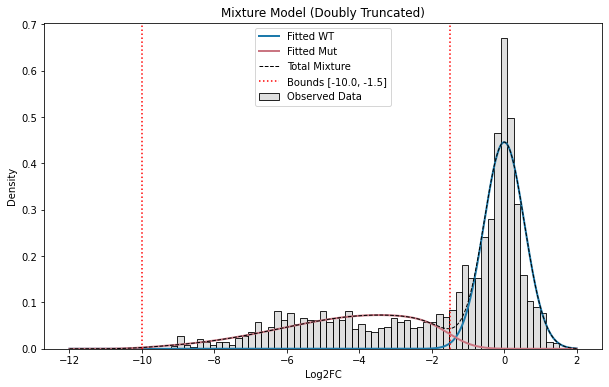


WT Cutoff (LLR > 3): -0.750
Mut Cutoff (LLR < -3): -1.736


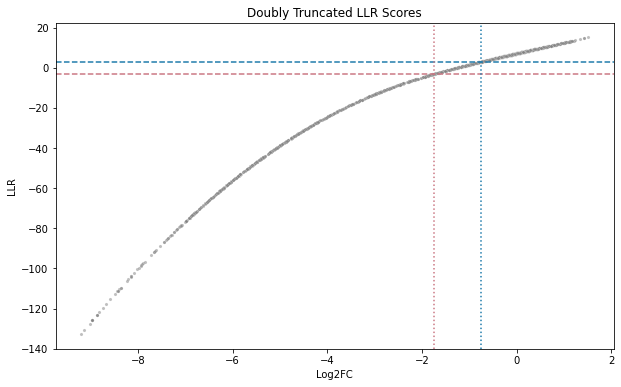

In [275]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
# Ensure df is available in your environment
if isinstance(df, pl.DataFrame):
    log2fc_values = df['log2fc'].drop_nulls().to_numpy()
else:
    log2fc_values = df['log2fc'].dropna().to_numpy()

# DEFINING BOUNDS
UPPER_BOUND = -1.5  # Hard biological limit (upper)
LOWER_BOUND = -10.0 # Hard biological limit (lower - detection limit)

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================

def log_diff_cdf(upper_z, lower_z):
    """
    Computes log(CDF(upper) - CDF(lower)) safely.
    Uses log-space arithmetic to prevent underflow.
    """
    # log_cdf_upper = log(P(Z < upper))
    # log_cdf_lower = log(P(Z < lower))
    # We want log(exp(log_cdf_upper) - exp(log_cdf_lower))
    
    log_u = stats.norm.logcdf(upper_z)
    log_l = stats.norm.logcdf(lower_z)
    
    # Use numpy's logaddexp to handle the subtraction safely in log space:
    # log(A - B) = log(A) + log(1 - exp(log(B) - log(A)))
    # Note: This assumes upper_z > lower_z. If not, return -inf.
    
    mask = (log_u > log_l)
    
    # Safe computation for valid ranges
    # We use a small epsilon for stability if needed, but direct formula usually works
    val = log_u + np.log1p(-np.exp(log_l - log_u))
    
    # If the interval is effectively zero or inverted, return extremely low log prob
    return np.where(mask, val, -np.inf)

def get_doubly_convolved_pdf(x_data, mu, sigma_bio, lower_b, upper_b, sigma_error):
    """
    Computes the PDF of a Doubly Truncated Normal (intrinsic) convolved with Normal (noise).
    
    P(y) = N(y | mu, sqrt(sigma_bio^2 + sigma_err^2)) * [Mass_Post / Mass_Prior]
    
    Where:
    - Mass_Prior: P(lower < X < upper) for the intrinsic distribution
    - Mass_Post:  P(lower < X < upper) for the posterior distribution P(x|y)
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    # A. Un-truncated Marginal Likelihood (The "Infinite" Case)
    log_py_unbounded = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)
    
    # B. Posterior Parameters (Where is the true value likely to be, given observed y?)
    #    New Mean = Weighted average of Prior Mean and Observed Data
    #    New Var  = Harmonic sum of variances
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)
    
    # C. Calculate Normalization Terms (Mass within bounds)
    
    # 1. Posterior Mass: Proportion of the posterior belief that falls inside [lower, upper]
    z_post_upper = (upper_b - mu_post) / sigma_post
    z_post_lower = (lower_b - mu_post) / sigma_post
    log_mass_post = log_diff_cdf(z_post_upper, z_post_lower)
    
    # 2. Prior Mass: Proportion of the original biological distribution inside [lower, upper]
    #    This is a constant scalar for given parameters, but calculated vectorized for safety
    z_prior_upper = (upper_b - mu) / sigma_bio
    z_prior_lower = (lower_b - mu) / sigma_bio
    log_mass_prior = log_diff_cdf(z_prior_upper, z_prior_lower)
    
    # D. Final Log PDF
    # log(P(y)) = log(P_unbounded) + log(Mass_Post) - log(Mass_Prior)
    log_result = log_py_unbounded + log_mass_post - log_mass_prior
    
    return np.exp(log_result)

def negative_log_likelihood(params):
    """
    Objective function for optimization with Double Truncation.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error = params
    
    # Constraints / Safety checks
    if sigma_wt < 0.01 or sigma_mut < 0.01 or w_mut < 0.01 or w_mut > 0.99 or sigma_error < 0.01:
        return np.inf
    
    # --- WT COMPONENT (Standard Normal) ---
    sigma_total_wt = np.sqrt(sigma_wt**2 + sigma_error**2)
    pdf_wt = stats.norm.pdf(log2fc_values, loc=0, scale=sigma_total_wt)
    
    # --- MUTANT COMPONENT (Doubly Truncated Convolution) ---
    pdf_mut = get_doubly_convolved_pdf(
        log2fc_values, 
        mu_mut, 
        sigma_mut, 
        LOWER_BOUND, 
        UPPER_BOUND, 
        sigma_error
    )
    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    
    return -np.sum(np.log(pdf_mix))

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error
initial_guess = [0.3, -6.0, 3.0, 0.2, 0.5]

bounds = [
    (0.01, 1.5),    # sigma_wt
    (-9.0, -3.0),   # mu_mut (Constrained slightly inside the bounds for stability)
    (0.5, 10.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.01, 2.0)     # sigma_error
]

print(f"Optimizing with bounds: [{LOWER_BOUND}, {UPPER_BOUND}]...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

opt_sigma_wt, opt_mu_mut, opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"WT Intrinsic Sigma:   {opt_sigma_wt:.4f}")
print(f"Mutant Mean:          {opt_mu_mut:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bounds:               [{LOWER_BOUND}, {UPPER_BOUND}]")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(log2fc_values, stat='density', bins=60, color='silver', alpha=0.5, label='Observed Data')

x_plot = np.linspace(LOWER_BOUND - 2, 2, 1000)

# WT Curve
sigma_total_wt = np.sqrt(opt_sigma_wt**2 + opt_sigma_error**2)
y_wt = (1 - opt_w_mut) * stats.norm.pdf(x_plot, loc=0, scale=sigma_total_wt)

# Mut Curve
y_mut_raw = get_doubly_convolved_pdf(
    x_plot, 
    opt_mu_mut, 
    opt_sigma_mut, 
    LOWER_BOUND, 
    UPPER_BOUND, 
    opt_sigma_error
)
y_mut = opt_w_mut * y_mut_raw

plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_wt + y_mut, color='black', linestyle='--', lw=1, label='Total Mixture')

# Draw Bounds
plt.axvline(UPPER_BOUND, color='red', linestyle=':', label=f'Bounds [{LOWER_BOUND}, {UPPER_BOUND}]')
plt.axvline(LOWER_BOUND, color='red', linestyle=':')

plt.title("Mixture Model (Doubly Truncated)")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr_doubly_truncated(df_in, mu_mut, sigma_mut, sigma_wt, lower_b, upper_b, sigma_error):
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()
        
    log2fc = df_out["log2fc"].to_numpy()
    
    # Handle row-specific error if available
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)
    row_error = np.maximum(row_error, 1e-3)

    # --- Null Hypothesis (WT) ---
    scale_wt = np.sqrt(row_error**2 + sigma_wt**2)
    loglik_wt = stats.norm.logpdf(log2fc, loc=0, scale=scale_wt)
    
    # --- Alt Hypothesis (Mutant) ---
    pdt_mut = get_doubly_convolved_pdf(log2fc, mu_mut, sigma_mut, lower_b, upper_b, row_error)
    loglik_mut = np.log(np.maximum(pdt_mut, 1e-100))
    
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut
    
    return pl.from_pandas(df_out)

df_result_pl = compute_perturbation_llr_doubly_truncated(
    df, 
    mu_mut=opt_mu_mut, 
    sigma_mut=opt_sigma_mut, 
    sigma_wt=opt_sigma_wt, 
    lower_b=LOWER_BOUND,
    upper_b=UPPER_BOUND, 
    sigma_error=opt_sigma_error
)
df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & PLOT
# ==========================================
# Sort strictly by LLR for clean interpolation
df_sorted = df_result.sort_values('perturbation_LLR')

# Filter for interpolation range to avoid errors if LLR doesn't reach +/-3
if df_sorted['perturbation_LLR'].min() < -3 and df_sorted['perturbation_LLR'].max() > 3:
    cutoff_wt = np.interp(3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])
    cutoff_mut = np.interp(-3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])
    print(f"\nWT Cutoff (LLR > 3): {cutoff_wt:.3f}")
    print(f"Mut Cutoff (LLR < -3): {cutoff_mut:.3f}")
else:
    print("\nWarning: LLR scores did not reach +/- 3 threshold.")
    cutoff_wt, cutoff_mut = 0, -3 # Fallback defaults

# Final LLR Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=10)
plt.axhline(3, color='#1D7AAB', ls='--')
plt.axhline(-3, color='#CA7682', ls='--')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("Doubly Truncated LLR Scores")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.show()